# 02 · YOLO detector: where is the problem, and what is it?

Stage 2 of the screening pipeline. Stage 1 (`01_issue_classifier.ipynb`) says *whether* a mouth photo shows a problem;
this model draws boxes around each finding and names it:

| id | class | in our feature list? |
|---|---|---|
| 0 | Calculus | yes |
| 1 | Caries | yes |
| 2 | Hypodontia (missing teeth) | no, kept so results stay comparable with the group's dataset |
| 3 | Mouth_Ulcer | yes |
| 4 | Tooth_Discoloration | yes |

**Data:** `datasets/oral_datasetv1.1/oral_dataset` (Daniel's v1.1 build). Model: Ultralytics **YOLO11n** (the
smallest version, pre-trained on everyday photos), fine-tuned at 640 px.

**Two problems in the dataset this notebook works around**

1. **Roboflow copies.** The 23,277 `roboflow_oral` photos are only about 7,400 different photos: Roboflow saved
   2-3 rotated / stretched / colour-shifted copies of each. The copies sit in the same split (no leakage), but they
   triple-count the test set and give Roboflow photos a recognisable look. → We keep **one copy per photo** in every
   split. YOLO makes its own random variations while training, so nothing useful is lost.
2. **The shared val/test sets are all Roboflow** (every photo with a condition). A model can score well there
   without working on normal clinical or phone photos. → We hold out patients from **Zenodo and DentalAI** (whose
   caries boxes were drawn by people) as a **fair test** (`test_fair`) and a **fair quiz** (added to `val`, which
   picks the best epoch).

**Scores reported**

- `test`: the shared test set, one copy per photo.
- `test_person`: the same, only photos labelled entirely by people.
- `test_fair`: the held-out Zenodo / DentalAI patients. **Quote this one first.** Only its *Caries* boxes are
  human-drawn; its other boxes were drawn by Qwen, so treat those classes' scores as rough.

Metrics: **mAP50** (how well boxes match, 0-1, higher is better), precision, recall, per class; plus an
image-level "any finding?" check so this model can be compared with the stage-1 classifier.

Set the environment variable `YOLO_SMOKE=1` for a 1-epoch run on a small sample (checks the notebook end to end).

## 0. Setup

In [1]:
import json, os, random, re, shutil, time
from concurrent.futures import ThreadPoolExecutor
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from PIL import Image, ImageDraw, ImageOps
from sklearn.metrics import roc_auc_score
from tqdm.auto import tqdm
import ultralytics
from ultralytics import YOLO

# Keep Windows from sleeping while this notebook runs (a sleep kills training). Lid-close still sleeps.
if os.name == "nt":
    import ctypes
    ctypes.windll.kernel32.SetThreadExecutionState(0x80000000 | 0x00000001)   # ES_CONTINUOUS | ES_SYSTEM_REQUIRED

print("torch", torch.__version__, "| ultralytics", ultralytics.__version__,
      "| GPU:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "none (CPU will be very slow)")

D:\nyp\Sem 2\AI Innovation Deep learning\.venv-train\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


torch 2.7.1+cu126 | ultralytics 8.4.210 | GPU: NVIDIA GeForce GTX 1050 Ti with Max-Q Design


## 1. Settings

In [2]:
SMOKE = os.environ.get("YOLO_SMOKE") == "1"

REPO = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "shared" / "conditions.yaml").exists())
DATA_DIR = Path(os.environ.get("YOLO_DATA", REPO.parent / "datasets" / "oral_datasetv1.1" / "oral_dataset"))
WORK = REPO.parent / "datasets" / "yolo_work_v1.1"     # resized copies + YOLO runs (outside the repo: large)

MODEL = "yolo11n.pt"     # n = nano, the smallest; fits a 4 GB GPU
IMGSZ = 640
BATCH = 16
EPOCHS = 1 if SMOKE else 30
PATIENCE = 10            # stop if the fair+shared val score hasn't improved for this many epochs
WORKERS = 8              # CPU processes preparing photos (the i7 has 12 threads)
SEED = 42
CONF = 0.25              # a box counts as a finding at this confidence or above

FAIR_SOURCES = ["zenodo", "dentalai"]   # human caries boxes, both healthy and problem photos
FAIR_FRAC = 0.30                        # share of their training photos held out (half quiz, half fair test)

EXPERIMENT = "Y1_yolo11n_640" + ("_smoke" if SMOKE else "")
OUT_DIR = REPO / "models" / "yolo_caries" / "results" / "Brandon"
WEIGHTS_DIR = REPO / "models" / "yolo_caries" / "weights" / "Brandon"
for d in (WORK, OUT_DIR, WEIGHTS_DIR, OUT_DIR / "figures"):
    d.mkdir(parents=True, exist_ok=True)

random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
NAMES = ["Calculus", "Caries", "Hypodontia", "Mouth_Ulcer", "Tooth_Discoloration"]
print("data:", DATA_DIR, "| work:", WORK, "| smoke:", SMOKE)

data: D:\nyp\Sem 2\AI Innovation Deep learning\datasets\oral_datasetv1.1\oral_dataset | work: D:\nyp\Sem 2\AI Innovation Deep learning\datasets\yolo_work_v1.1 | smoke: False


## 2. Load the label sheet and make the splits

Steps:
1. Keep each Zenodo **patient** inside one split (their file names carry the patient id).
2. Hold out whole patients / copy groups from Zenodo and DentalAI training photos → half to `val_fair`
   (joins the quiz), half to `test_fair`.
3. Keep **one copy per Roboflow photo** in every split.
4. Training uses only rows marked `in_yolo` (the dataset caps healthy mouths at about 10% for YOLO; a detector shown
   too many empty photos learns to stay quiet).

In [3]:
df = pd.read_csv(DATA_DIR / "labels.csv")

def patient_id(src):   # e.g. anonymous_003-007-1214-00_... → p003-007-1214
    m = re.search(r"anonymous_(\d+)[-_](\d+)[-_](\d+)", str(src))
    return "p" + "-".join(m.groups()) if m else None

df["patient"] = [patient_id(s) for s in df["source_file"]]

# 1. a patient seen in val/test never trains
eval_patients = set(df.loc[df.split != "train", "patient"].dropna())
leak = df.split.eq("train") & df.patient.isin(eval_patients)
print("train photos dropped because their patient is in val/test:", int(leak.sum()))
df = df[~leak].copy()

# 2. fair hold-out: whole patients (Zenodo) or copy groups, from the fair sources' training photos
in_train = df.split.eq("train")
unit = df.patient.fillna("g" + df.group.astype(str))
cand = unit[in_train & df.dataset.isin(FAIR_SOURCES)]
sizes = cand.value_counts()
order = sizes.index.to_numpy().copy(); np.random.default_rng(SEED).shuffle(order)
held_units, n = [], 0
for u in order:
    if n >= FAIR_FRAC * len(cand):
        break
    if sizes[u] <= 50:
        held_units.append(u); n += sizes[u]
to_val = set(held_units[0::2])          # alternate units: quiz / fair test
held = in_train & unit.isin(held_units)
while True:   # pull in every copy and every other photo of the same patient
    grow = in_train & (df.group.isin(df.loc[held, "group"]) | df.patient.isin(df.loc[held, "patient"].dropna()))
    if grow.sum() == held.sum():
        break
    held = grow
# a grown row follows the unit it is connected to (by patient, else by group)
unit_of_group = dict(zip(df.loc[held & unit.isin(held_units), "group"], unit[held & unit.isin(held_units)]))
held_set = set(held_units)
def fair_split(i):
    u = unit[i] if unit[i] in held_set else unit_of_group.get(df.at[i, "group"], held_units[0])
    return "val_fair" if u in to_val else "test_fair"
for i in df.index[held]:
    df.at[i, "split"] = fair_split(i) if df.at[i, "dataset"] in FAIR_SOURCES else "unused"
df = df[df.split != "unused"]

# 3. one copy per Roboflow photo
robo = df.dataset.eq("roboflow_oral")
df = pd.concat([df[~robo], df[robo].sort_values("md5").drop_duplicates(["split", "group"])]).reset_index(drop=True)

# 4. training: YOLO rows only
df = df[~(df.split.eq("train") & df.in_yolo.eq(0))].reset_index(drop=True)

if SMOKE:   # small sample, every split and source represented
    df = pd.concat([g.sample(min(len(g), 300 if k[0] == "train" else 60), random_state=SEED)
                    for k, g in df.groupby(["split", "has_issue"])]).reset_index(drop=True)

SETS = {"train": ["train"], "val": ["val", "val_fair"], "test": ["test"], "test_fair": ["test_fair"]}
df["set"] = df.split.map({s: k for k, v in SETS.items() for s in v})
display(pd.crosstab(df.dataset, df.split, margins=True))

train photos dropped because their patient is in val/test: 17


split,test,test_fair,train,val,val_fair,All
dataset,,,,,,
dentalai,92,341,1341,91,334,2199
external_clean,6,0,345,6,0,357
kaggle_oral,60,0,809,59,0,928
mendeley_noncaries,435,0,2018,478,0,2931
roboflow_oral,737,0,5894,737,0,7368
zenodo,6,431,1182,6,572,2197
All,1336,772,11589,1377,906,15980


### Leakage check (should all be 0) and what each set holds

In [4]:
train_mask = df.set.eq("train")
for col in ("group", "patient", "md5"):
    a = set(df.loc[train_mask, col].dropna()); b = set(df.loc[~train_mask, col].dropna())
    print(f"{col:8s} shared between train and val/test: {len(a & b)}")
a = set(df.loc[df.set.eq("val"), "group"]); b = set(df.loc[df.set.isin(["test", "test_fair"]), "group"])
print("group    shared between val and the tests:", len(a & b))

summary = df.groupby("set").agg(photos=("md5", "size"), with_condition=("has_issue", "sum"),
                                person_labelled=("label_by", lambda s: (s == "person").sum()))
for c in NAMES:
    summary[c] = df.groupby("set")[c].sum()
display(summary.loc[["train", "val", "test", "test_fair"]])

group    shared between train and val/test: 0
patient  shared between train and val/test: 0
md5      shared between train and val/test: 0
group    shared between val and the tests: 6


,photos,with_condition,person_labelled,Calculus,Caries,Hypodontia,Mouth_Ulcer,Tooth_Discoloration
set,,,,,,,,
train,11589,9164,5963,1070,4721,549,1929,2808
val,2283,1517,796,120,1057,67,205,320
test,1336,737,797,117,274,65,202,264
test_fair,772,658,0,4,650,0,1,36


## 3. Make resized copies for YOLO

Photos range from 300 px to 7,000 px. Decoding the big ones every epoch would make the GPU wait, so each photo is
saved once at 640 px on its longest side (EXIF rotation applied, the same way the boxes were drawn). Box
coordinates are fractions of the image size, so they stay valid. Copies go to `datasets/yolo_work_v1.1/`.

In [5]:
def src_label(img_rel):
    return DATA_DIR / Path(img_rel.replace("images/", "labels/", 1)).with_suffix(".txt")

def cache_one(row):
    img_dst = WORK / "images" / row.set / f"{row.md5}.jpg"
    lab_dst = WORK / "labels" / row.set / f"{row.md5}.txt"
    if not img_dst.exists():
        try:
            with Image.open(DATA_DIR / row.image) as im:
                if im.format == "JPEG":
                    im.draft("RGB", (IMGSZ * 2, IMGSZ * 2))
                im = ImageOps.exif_transpose(im).convert("RGB")
                im.thumbnail((IMGSZ, IMGSZ), Image.LANCZOS)
                tmp = img_dst.with_suffix(".tmp"); im.save(tmp, format="JPEG", quality=95); tmp.replace(img_dst)
        except Exception as e:
            return f"{row.image}: {e}"
    shutil.copyfile(src_label(row.image), lab_dst)
    return None

for s in SETS:   # clear files from earlier runs that are no longer in a set
    for kind in ("images", "labels"):
        d = WORK / kind / s; d.mkdir(parents=True, exist_ok=True)
        keep = set(df.loc[df.set == s, "md5"])
        for f in d.iterdir():
            if f.stem not in keep:
                f.unlink()
    for f in (WORK / "labels").glob("*.cache"):
        f.unlink()

t0 = time.time()
with ThreadPoolExecutor(8) as ex:
    errors = [e for e in tqdm(ex.map(cache_one, df.itertuples()), total=len(df)) if e]
print(f"cached {len(df)} photos in {time.time() - t0:.0f}s; unreadable: {len(errors)}", errors[:5])
df = df[~df.image.isin([e.split(':')[0] for e in errors])].reset_index(drop=True)
df["path"] = [str(WORK / "images" / s / f"{m}.jpg") for s, m in zip(df.set, df.md5)]

  0%|          | 0/15980 [00:00<?, ?it/s]

  1%|          | 112/15980 [00:00<00:14, 1084.19it/s]

  1%|▏         | 221/15980 [00:00<00:15, 993.31it/s] 

  2%|▏         | 321/15980 [00:00<00:16, 963.67it/s]

  3%|▎         | 418/15980 [00:00<00:17, 909.08it/s]

  3%|▎         | 510/15980 [00:00<00:18, 849.88it/s]

... (124 outputs left out)

 98%|█████████▊| 15738/15980 [00:14<00:00, 1589.26it/s]

 99%|█████████▉| 15898/15980 [00:14<00:00, 1591.66it/s]

100%|██████████| 15980/15980 [00:14<00:00, 1117.87it/s]

cached 15980 photos in 15s; unreadable: 0 []


### Dataset config files

In [6]:
def write_yaml(name, val_source, test_source=None):
    p = WORK / f"{name}.yaml"
    p.write_text(f"path: {WORK.as_posix()}\ntrain: images/train\nval: {val_source}\n"
                 + (f"test: {test_source}\n" if test_source else "")
                 + f"nc: {len(NAMES)}\nnames: {json.dumps(NAMES)}\n")
    return p

person_list = WORK / "test_person.txt"
person_list.write_text("\n".join(df.loc[df.set.eq("test") & df.label_by.eq("person"), "path"]) + "\n")
DATA_YAML = write_yaml("train", "images/val", "images/test")
EVAL_YAMLS = {"test": write_yaml("eval_test", "images/test"),
              "test_person": write_yaml("eval_test_person", person_list.name),
              "test_fair": write_yaml("eval_test_fair", "images/test_fair")}
print(DATA_YAML.read_text())

path: D:/nyp/Sem 2/AI Innovation Deep learning/datasets/yolo_work_v1.1
train: images/train
val: images/val
test: images/test
nc: 5
names: ["Calculus", "Caries", "Hypodontia", "Mouth_Ulcer", "Tooth_Discoloration"]



## 4. Look at some training photos with their boxes

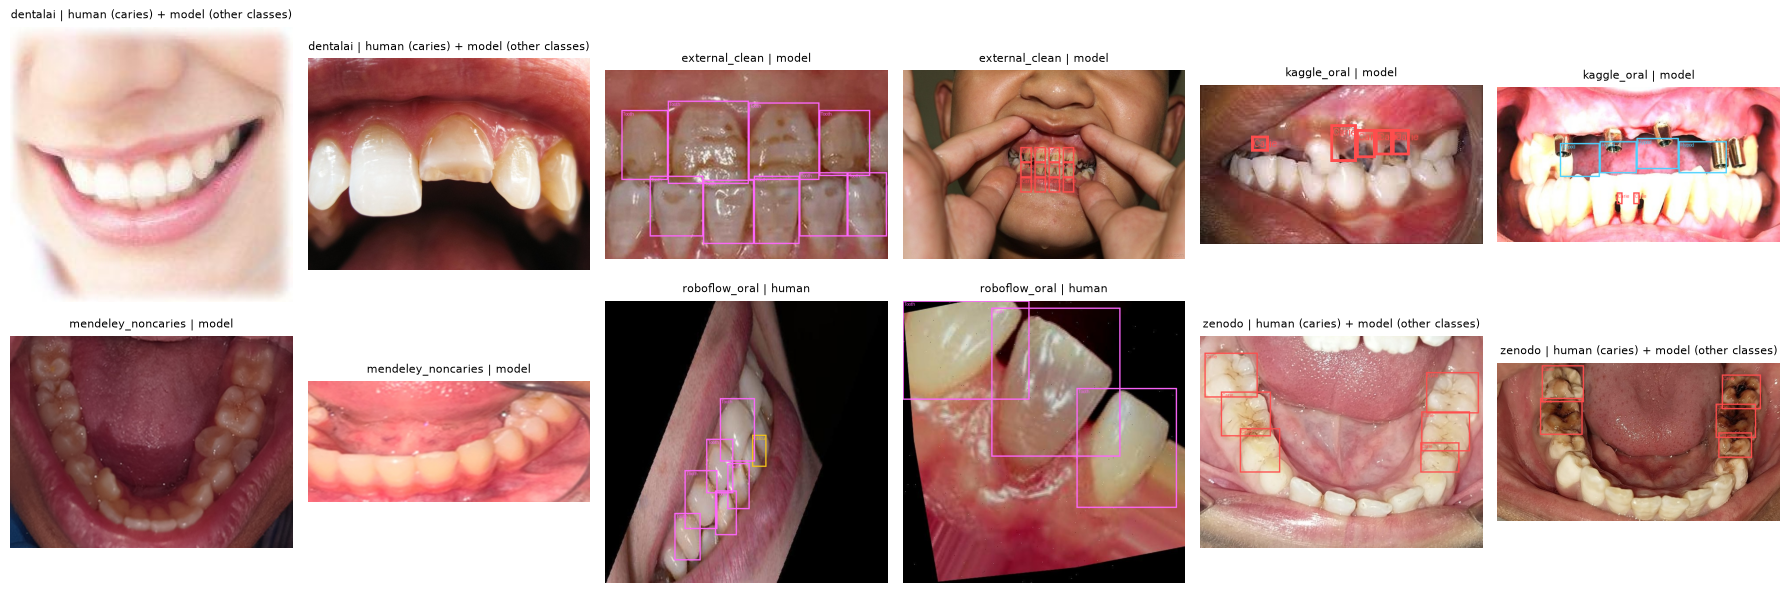

legend: {'Calculus': '#f5c518', 'Caries': '#ff4d4d', 'Hypodontia': '#4dd2ff', 'Mouth_Ulcer': '#7CFC00', 'Tooth_Discoloration': '#ff66ff'}


In [7]:
COLORS = ["#f5c518", "#ff4d4d", "#4dd2ff", "#7CFC00", "#ff66ff"]

def draw(path, boxes, title=None, ax=None):
    """boxes: rows of (cls, cx, cy, w, h[, conf]) with coordinates as fractions."""
    im = Image.open(path).convert("RGB"); W, H = im.size; d = ImageDraw.Draw(im)
    for b in boxes:
        c, cx, cy, w, h = b[:5]
        d.rectangle([(cx - w / 2) * W, (cy - h / 2) * H, (cx + w / 2) * W, (cy + h / 2) * H],
                    outline=COLORS[int(c)], width=3)
        d.text(((cx - w / 2) * W + 3, (cy - h / 2) * H + 2),
               NAMES[int(c)][:5] + (f" {b[5]:.2f}" if len(b) > 5 else ""), fill=COLORS[int(c)])
    ax.imshow(im); ax.axis("off")
    if title: ax.set_title(title, fontsize=8)

def read_boxes(path):
    lab = Path(path.replace(os.sep + "images" + os.sep, os.sep + "labels" + os.sep)).with_suffix(".txt")
    return [list(map(float, l.split())) for l in lab.read_text().splitlines() if l.strip()]

sample = pd.concat([g.sample(min(len(g), 2), random_state=1) for _, g in df[df.set == "train"].groupby("dataset")])
fig, axes = plt.subplots(2, 6, figsize=(18, 6))
for ax, r in zip(axes.flat, sample.itertuples()):
    draw(r.path, read_boxes(r.path), f"{r.dataset} | {r.boxes_by}", ax)
for ax in axes.flat[len(sample):]: ax.axis("off")
plt.tight_layout(); plt.show()
print("legend:", {n: c for n, c in zip(NAMES, COLORS)})

## 5. Train

If an earlier run with the same name was interrupted (e.g. the laptop slept), it **resumes** from its last
saved epoch instead of starting over.

YOLO11n starts from weights pre-trained on everyday photos (COCO). Every epoch it sees each training photo once,
with its own random changes (mosaic of 4 photos, flips, scaling, colour). After each epoch it is scored on `val`
(shared val + fair quiz) and the best epoch is kept as `best.pt`. Training stops early if `val` stops improving.

In [8]:
last = WORK / "runs" / EXPERIMENT / "weights" / "last.pt"
done_epochs = len(pd.read_csv(last.parent.parent / "results.csv")) if last.exists() else 0
t0 = time.time()
if last.exists() and done_epochs < EPOCHS:
    ckpt = torch.load(last, map_location="cpu", weights_only=False)
    if ckpt.get("epoch", -1) >= 0:   # -1 means that run already finished
        print(f"resuming interrupted run after epoch {done_epochs}")
        ckpt["train_args"].update(epochs=EPOCHS, workers=WORKERS, patience=PATIENCE)
        torch.save(ckpt, last)
        model = YOLO(str(last))
        train_res = model.train(resume=True)
    else:
        last = None
else:
    last = None
if last is None:
    model = YOLO(str(WORK / MODEL))     # downloads the pre-trained weights the first time
    train_res = model.train(data=str(DATA_YAML), epochs=EPOCHS, imgsz=IMGSZ, batch=BATCH, workers=WORKERS,
                            patience=PATIENCE, seed=SEED, cos_lr=True, project=str(WORK / "runs"), name=EXPERIMENT,
                            exist_ok=True, plots=True, verbose=False)
train_minutes = (time.time() - t0) / 60
RUN_DIR = Path(model.trainer.save_dir)
BEST = RUN_DIR / "weights" / "best.pt"
print(f"trained for {train_minutes:.0f} min in this session → {BEST}")

resuming interrupted run after epoch 28


New https://pypi.org/project/ultralytics/8.4.212 available  Update with 'pip install -U ultralytics'


Ultralytics 8.4.210  Python-3.13.7 torch-2.7.1+cu126 CUDA:0 (NVIDIA GeForce GTX 1050 Ti with Max-Q Design, 4096MiB)


engine\trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=True, cutmix=0.0, data=D:\nyp\Sem 2\AI Innovation Deep learning\datasets\yolo_work_v1.1\train.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=30, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=None, kobj=1.0, line_width=None, lr0=0.001111, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=D:\nyp\Sem 2\AI Innovation Deep learning\datasets\yolo_work_v1.1\runs\Y1_yolo11n_640\weights\last.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=Y1_yo


                   from  n    params  module                                       arguments                     


  0                  -1  1       464  ultralytics.nn.modules.conv.Conv             [3, 16, 3, 2]                 


... (1,976 outputs left out)

                   all       2283       6209       0.62      0.618      0.641      0.345


Speed: 0.3ms preprocess, 7.9ms inference, 0.0ms loss, 4.1ms postprocess per image


Results saved to D:\nyp\Sem 2\AI Innovation Deep learning\datasets\yolo_work_v1.1\runs\Y1_yolo11n_640


trained for 26 min in this session → D:\nyp\Sem 2\AI Innovation Deep learning\datasets\yolo_work_v1.1\runs\Y1_yolo11n_640\weights\best.pt


### Training curves (`box_loss` = how far boxes are off, `cls_loss` = naming mistakes, `mAP50` on val)

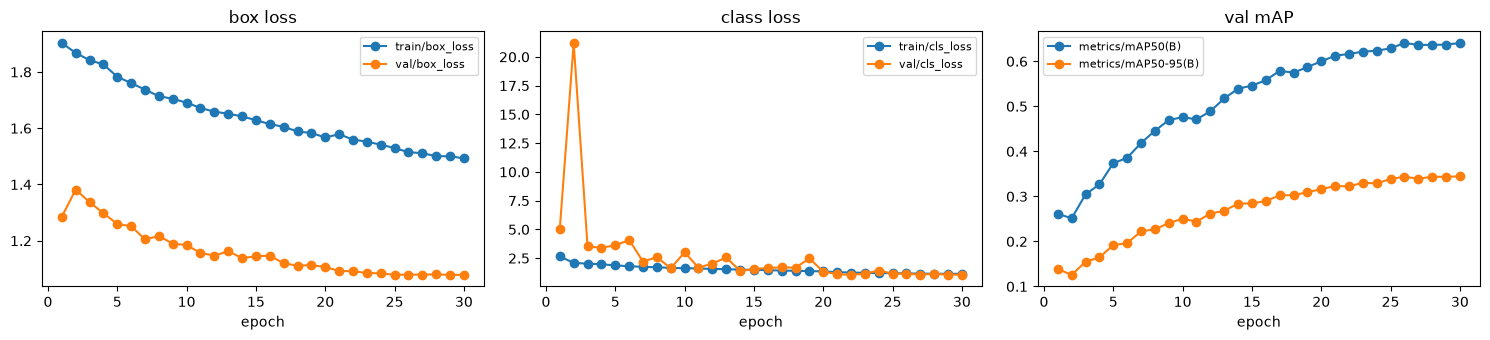

best epoch by val mAP50: 26 of 30


In [9]:
hist = pd.read_csv(RUN_DIR / "results.csv"); hist.columns = hist.columns.str.strip()
fig, axes = plt.subplots(1, 3, figsize=(15, 3.5))
for ax, (cols, title) in zip(axes, [(["train/box_loss", "val/box_loss"], "box loss"),
                                     (["train/cls_loss", "val/cls_loss"], "class loss"),
                                     (["metrics/mAP50(B)", "metrics/mAP50-95(B)"], "val mAP")]):
    for c in cols:
        ax.plot(hist.epoch, hist[c], marker="o", label=c)
    ax.set_title(title); ax.set_xlabel("epoch"); ax.legend(fontsize=8)
plt.tight_layout(); fig.savefig(OUT_DIR / "figures" / f"{EXPERIMENT}_curves.png", dpi=120); plt.show()
best_epoch = int(hist.loc[hist["metrics/mAP50(B)"].idxmax(), "epoch"])
print("best epoch by val mAP50:", best_epoch, "of", len(hist))

## 6. Box scores on the three test sets

`mAP50`: for each class, how well the boxes match people's boxes (a box counts if it overlaps at least 50%),
averaged over classes. 1.0 is perfect. `precision`: of the boxes drawn, how many were right. `recall`: of the real
findings, how many got a box.

In [10]:
best = YOLO(str(BEST))
box_results, per_class = {}, []
for name, yml in EVAL_YAMLS.items():
    m = best.val(data=str(yml), split="val", imgsz=IMGSZ, batch=BATCH, workers=WORKERS, plots=True,
                 project=str(WORK / "runs"), name=f"{EXPERIMENT}_{name}", exist_ok=True, verbose=False)
    box_results[name] = dict(mAP50=float(m.box.map50), mAP50_95=float(m.box.map),
                             precision=float(m.box.mp), recall=float(m.box.mr))
    for i, c in enumerate(m.box.ap_class_index):
        per_class.append(dict(set=name, cls=NAMES[int(c)], AP50=float(m.box.ap50[i]),
                              precision=float(m.box.p[i]), recall=float(m.box.r[i])))
box_df = pd.DataFrame(box_results).T[["mAP50", "mAP50_95", "precision", "recall"]]
class_df = pd.DataFrame(per_class).pivot(index="cls", columns="set", values="AP50").reindex(NAMES)
display(box_df.round(3))
print("AP50 per class (test_fair: only Caries boxes are human-drawn)")
display(class_df.round(3))

Ultralytics 8.4.210  Python-3.13.7 torch-2.7.1+cu126 CUDA:0 (NVIDIA GeForce GTX 1050 Ti with Max-Q Design, 4096MiB)


YOLO11n summary (fused): 101 layers, 2,598,023 parameters, 0 gradients, 6.4 GFLOPs


val: Fast image access  (ping: 0.5±0.1 ms, read: 61.5±19.8 MB/s, size: 53.2 KB)


val: Scanning D:\nyp\Sem 2\AI Innovation Deep learning\datasets\yolo_work_v1.1\labels\test... 58 images, 10 backgrounds, 0 corrupt: 4% ╸─────────── 58/1336 165.1it/s 0.1s<7.7s

val: Scanning D:\nyp\Sem 2\AI Innovation Deep learning\datasets\yolo_work_v1.1\labels\test... 113 images, 20 backgrounds, 0 corrupt: 8% ━─────────── 113/1336 274.4it/s 0.2s<4.5s

val: Scanning D:\nyp\Sem 2\AI Innovation Deep learning\datasets\yolo_work_v1.1\labels\test... 161 images, 29 backgrounds, 0 corrupt: 12% ━─────────── 161/1336 330.5it/s 0.3s<3.6s

... (262 outputs left out)

Results saved to D:\nyp\Sem 2\AI Innovation Deep learning\datasets\yolo_work_v1.1\runs\Y1_yolo11n_640_test_fair


,mAP50,mAP50_95,precision,recall
test,0.685,0.335,0.675,0.624
test_person,0.688,0.337,0.679,0.624
test_fair,0.204,0.146,0.226,0.221


AP50 per class (test_fair: only Caries boxes are human-drawn)


set,test,test_fair,test_person
cls,,,
Calculus,0.426,0.001,0.426
Caries,0.749,0.745,0.757
Hypodontia,0.563,NaN,0.564
Mouth_Ulcer,0.833,0.001,0.833
Tooth_Discoloration,0.854,0.071,0.858


## 7. Image-level check: does it find *anything* on problem photos, and stay quiet on healthy ones?

This turns the detector into a yes/no screen (any box at confidence ≥ `CONF` → "problem"), so it can be compared
directly with the stage-1 classifier. ROC-AUC uses the most confident box per photo.

In [11]:
def predict_set(paths):
    out = []
    for i in range(0, len(paths), 64):
        for r in best.predict(paths[i:i + 64], imgsz=IMGSZ, conf=0.01, verbose=False, stream=True):
            b = r.boxes
            out.append(dict(max_conf=float(b.conf.max()) if len(b) else 0.0,
                            boxes=[[int(c), *map(float, xywh), float(cf)]
                                   for c, xywh, cf in zip(b.cls.tolist(), b.xywhn.tolist(), b.conf.tolist()) if cf >= CONF]))
    return out

eval_df = df[df.set.isin(["test", "test_fair"])].reset_index(drop=True)
preds = predict_set(eval_df.path.tolist())
eval_df["max_conf"] = [p["max_conf"] for p in preds]
eval_df["pred_boxes"] = [p["boxes"] for p in preds]
eval_df["flagged"] = (eval_df.max_conf >= CONF).astype(int)

def image_scores(g):
    y, p = g.has_issue.values, g.flagged.values
    rec = lambda cls: float((p[y == cls] == cls).mean()) if (y == cls).any() else float("nan")
    return dict(n=len(g), n_issue=int(y.sum()), n_healthy=int((1 - y).sum()), recall_issue=rec(1),
                recall_healthy=rec(0), balanced_accuracy=np.nanmean([rec(1), rec(0)]),
                roc_auc=float(roc_auc_score(y, g.max_conf)) if 0 < y.sum() < len(y) else float("nan"))

image_results = {s: image_scores(g) for s, g in eval_df.groupby("set")}
image_results["test_person"] = image_scores(eval_df[eval_df.set.eq("test") & eval_df.label_by.eq("person")])
display(pd.DataFrame(image_results).T.round(3))
by_source = pd.DataFrame({(s, src): image_scores(g) for (s, src), g in eval_df.groupby(["set", "dataset"])}).T
display(by_source.round(3))

,n,n_issue,n_healthy,recall_issue,recall_healthy,balanced_accuracy,roc_auc
test,1336.0,737.0,599.0,0.944,0.958,0.951,0.992
test_fair,772.0,658.0,114.0,0.898,0.868,0.883,0.951
test_person,797.0,737.0,60.0,0.944,0.817,0.881,0.981


n  n_issue  n_healthy  recall_issue  \
test      dentalai             92.0      0.0       92.0           NaN   
          external_clean        6.0      0.0        6.0           NaN   
          kaggle_oral          60.0      0.0       60.0           NaN   
          mendeley_noncaries  435.0      0.0      435.0           NaN   
          roboflow_oral       737.0    737.0        0.0         0.944   
          zenodo                6.0      0.0        6.0           NaN   
test_fair dentalai            341.0    236.0      105.0         0.737   
          zenodo              431.0    422.0        9.0         0.988   

                              recall_healthy  balanced_accuracy  roc_auc  
test      dentalai                     0.891              0.891      NaN  
          external_clean               0.833              0.833      NaN  
          kaggle_oral                  0.817              0.817      NaN  
          mendeley_noncaries           0.995              0.995      NaN  
          roboflow_oral                  NaN              0.944      NaN  
          zenodo                       0.833              0.833      NaN  
test_fair dentalai                     0.905              0.821    0.918  
          zenodo                       0.444              0.716    0.861

## 8. Examples from the fair test: people's boxes (left) vs the model's (right)

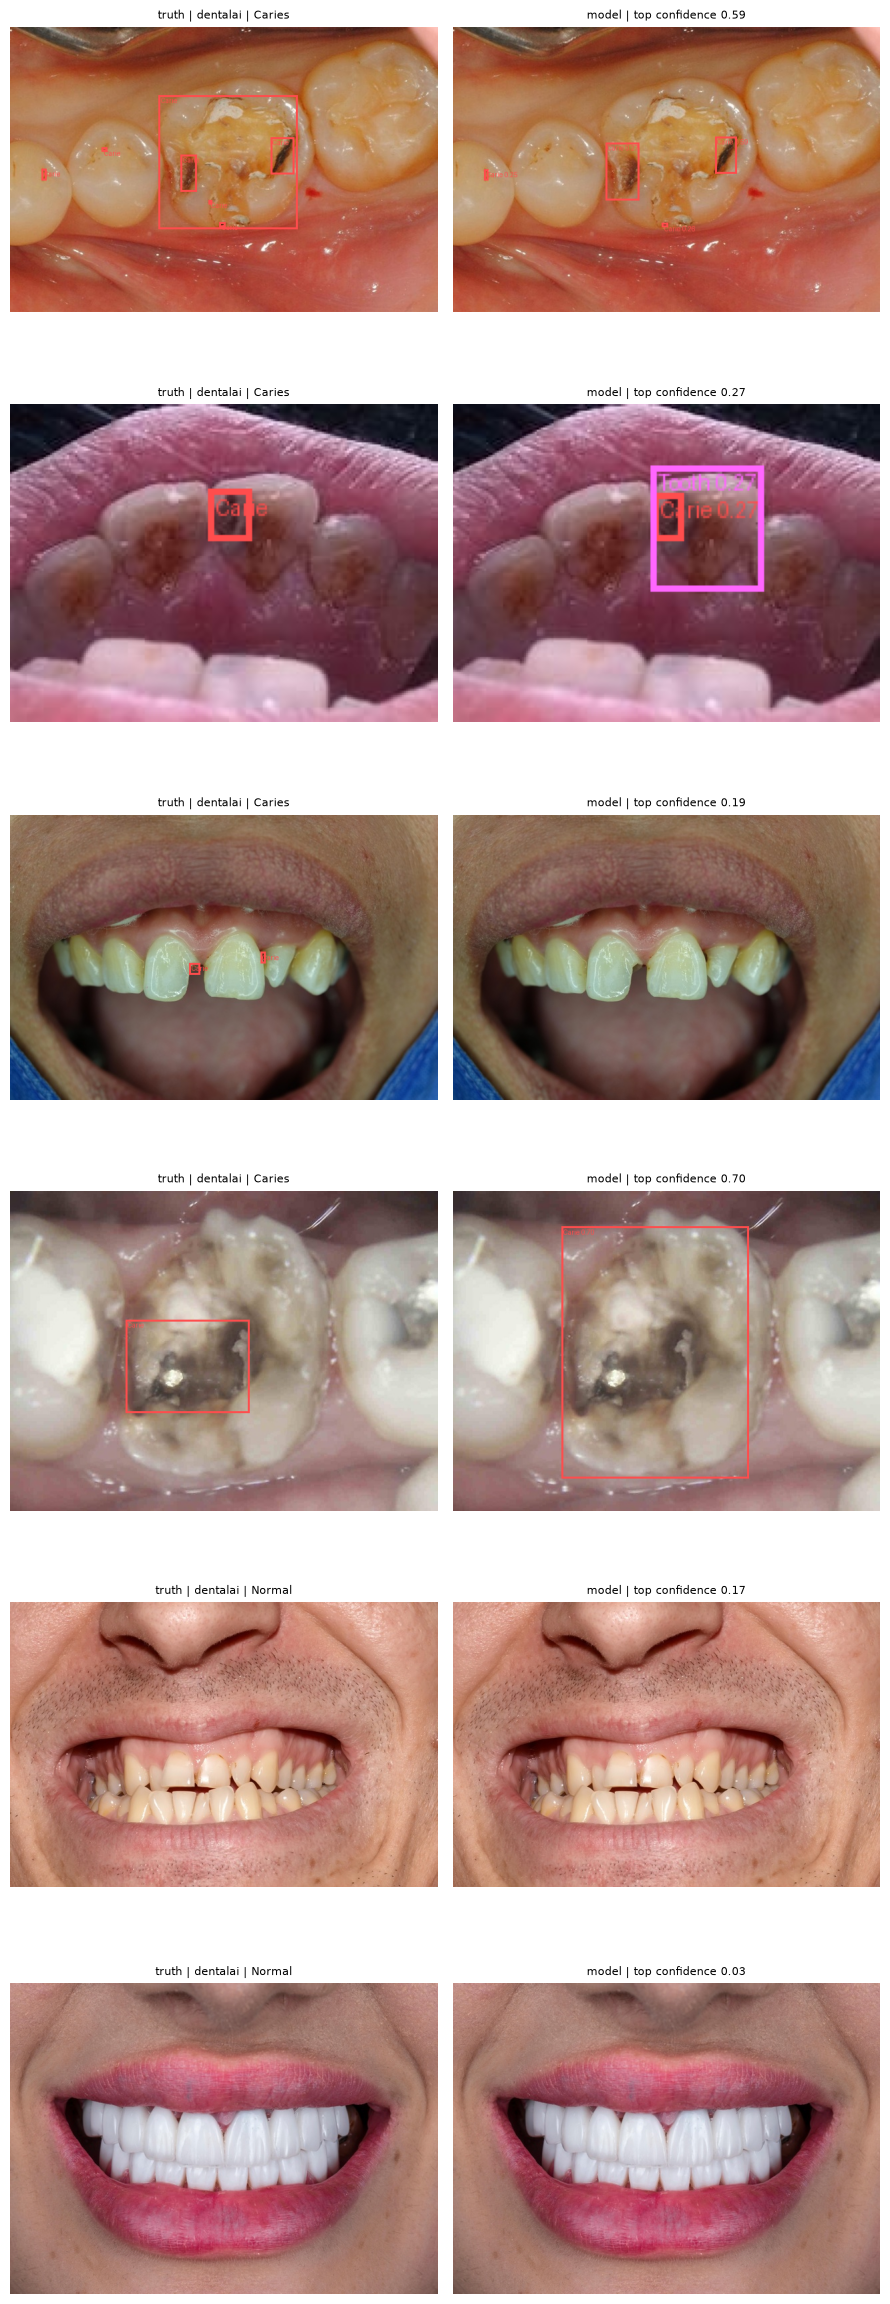

In [12]:
ex = pd.concat([eval_df[(eval_df.set == "test_fair") & (eval_df.has_issue == 1)].pipe(lambda g: g.sample(min(len(g), 4), random_state=3)),
                eval_df[(eval_df.set == "test_fair") & (eval_df.has_issue == 0)].pipe(lambda g: g.sample(min(len(g), 2), random_state=3))])
fig, axes = plt.subplots(len(ex), 2, figsize=(9, 4 * len(ex)))
for (a1, a2), r in zip(axes, ex.itertuples()):
    draw(r.path, read_boxes(r.path), f"truth | {r.dataset} | {r.labels}", a1)
    draw(r.path, r.pred_boxes, f"model | top confidence {r.max_conf:.2f}", a2)
plt.tight_layout(); fig.savefig(OUT_DIR / "figures" / f"{EXPERIMENT}_examples.png", dpi=100); plt.show()

## 9. Save the model and results

In [13]:
weights_out = WEIGHTS_DIR / ("yolo_detector_smoke.pt" if SMOKE else "yolo_detector.pt")
shutil.copyfile(BEST, weights_out)
for f in ("results.png", "confusion_matrix_normalized.png", "BoxPR_curve.png"):
    if (RUN_DIR / f).exists():
        shutil.copyfile(RUN_DIR / f, OUT_DIR / "figures" / f"{EXPERIMENT}_{f}")

metrics = dict(experiment=EXPERIMENT, data=str(DATA_DIR), model=MODEL, imgsz=IMGSZ, epochs_run=len(hist),
               best_epoch=best_epoch, train_minutes=round(train_minutes, 1), conf=CONF,
               set_sizes=summary["photos"].to_dict(), box=box_results,
               per_class_AP50=class_df.round(4).where(class_df.notna(), None).to_dict(),
               image_level=image_results,
               image_level_by_source={f"{s}/{src}": v for (s, src), v in by_source.to_dict("index").items()},
               notes="test_fair = held-out Zenodo/DentalAI patients; only Caries boxes there are human-drawn.")
(OUT_DIR / f"{EXPERIMENT}_metrics.json").write_text(json.dumps(metrics, indent=2, default=float))
hist.to_csv(OUT_DIR / f"{EXPERIMENT}_history.csv", index=False)

f, t = box_results["test_fair"], box_results["test"]
row = dict(run_id=EXPERIMENT, date=time.strftime("%Y-%m-%d"), member="Brandon", model=MODEL.replace(".pt", ""),
           data_version="oral_dataset v1.1 (Roboflow deduped, fair hold-out)", imgsz=IMGSZ, epochs=len(hist),
           batch=BATCH, lr0=model.trainer.args.lr0, mAP50=round(f["mAP50"], 4), mAP50_95=round(f["mAP50_95"], 4),
           precision=round(f["precision"], 4), recall=round(f["recall"], 4),
           weights_path=str(weights_out.relative_to(REPO)),
           notes=f"scores = test_fair; shared test mAP50 {t['mAP50']:.3f}; best epoch {best_epoch}")
log = REPO / "models" / "yolo_caries" / "results" / "experiments.csv"
pd.concat([pd.read_csv(log), pd.DataFrame([row])]).to_csv(log, index=False)
print("saved", weights_out, "and", OUT_DIR / f"{EXPERIMENT}_metrics.json")

saved D:\nyp\Sem 2\AI Innovation Deep learning\Deep-Learning-WIU\models\yolo_caries\weights\Brandon\yolo_detector.pt and D:\nyp\Sem 2\AI Innovation Deep learning\Deep-Learning-WIU\models\yolo_caries\results\Brandon\Y1_yolo11n_640_metrics.json


## 10. Try it on one photo

In [14]:
def detect(path, conf=CONF):
    """What the app would call: boxes with condition names and confidences (a screening aid, not a diagnosis)."""
    r = best.predict(str(path), imgsz=IMGSZ, conf=conf, verbose=False)[0]
    return [dict(condition=NAMES[int(c)], confidence=round(float(cf), 3), box_xyxy=[round(v) for v in b])
            for c, cf, b in zip(r.boxes.cls.tolist(), r.boxes.conf.tolist(), r.boxes.xyxy.tolist())]

demo = eval_df[(eval_df.set == "test_fair") & (eval_df.has_issue == 1)].iloc[0]
print(demo.labels); detect(demo.path)

Caries


[{'condition': 'Caries', 'confidence': 0.89, 'box_xyxy': [502, 304, 622, 390]},
 {'condition': 'Caries', 'confidence': 0.369, 'box_xyxy': [18, 282, 150, 387]}]

## 11. Results and limitations

| | test_fair (quote first) | test (shared) | test_person |
|---|---|---|---|
| mAP50 | | | |
| precision | | | |
| recall | | | |
| image level: problem photos flagged | | | |
| image level: healthy photos left alone | | | |

**Limitations to state in the report**
- The shared val/test sets hold only Roboflow photos with conditions; `test_fair` avoids that, but is only Zenodo
  and DentalAI (clinical photos), not phone selfies.
- In `test_fair` only Caries boxes are human-drawn; Calculus / Ulcer / Discolouration boxes there come from Qwen.
- Some training boxes (Kaggle, Mendeley, web images, non-caries boxes on Zenodo / DentalAI) were drawn by Qwen and
  may be wrong.
- Roboflow photos are pre-distorted (stretched to 640×640, tilted, colour-shifted) and include a few unrelated
  images.
- Hypodontia is not in the app's feature list; the app can ignore that class.